# Model Evaluation

## Objective

This notebook evaluates the performance of the selected Logistic Regression model for predicting in-hospital mortality using information available within the first 24 hours of admission.

The model will be assessed using the held-out test set, which was excluded from model training and cross-validation. Evaluation will consider multiple performance metrics, with particular attention to mortality recall, false negatives, and the trade-off between sensitivity and specificity.

The results will be interpreted cautiously because the MIMIC-III demo dataset contains a small number of admissions and mortality events.

## Loading the test data

In [1]:
import pandas as pd
import numpy as np

final_data = pd.read_csv("../data/processed/final_data.csv")

lab_columns = [
    "bicarbonate", "calcium", "creatinine", "glucose",
    "magnesium", "potassium", "sodium", "urea_nitrogen",
    "haematocrit", "haemoglobin", "platelet_count",
    "rdw", "white_blood_cells"
]

numerical_features = ["age_at_admission"] + lab_columns
categorical_features = ["gender", "diagnosis_category_model"]
feature_columns = numerical_features + categorical_features

X_raw = final_data[feature_columns].copy()
y_raw = final_data["hospital_expire_flag"]

from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_raw
)

In [2]:
print("Training features:", X_train_raw.shape)
print("Test features:", X_test_raw.shape)
print("Training outcomes:", y_train_raw.shape)
print("Test outcomes:", y_test_raw.shape)

Training features: (103, 16)
Test features: (26, 16)
Training outcomes: (103,)
Test outcomes: (26,)


## Creating pipelines

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

In [4]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

In [5]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression())
])

In [6]:
logistic_pipeline.fit(X_train_raw, y_train_raw)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age_at_admission','bicarbonate','calcium',...,'white_blood_cells', 'gender','diagnosis_category_model']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [7]:
y_pred = logistic_pipeline.predict(X_test_raw)

In [8]:
y_proba = logistic_pipeline.predict_proba(X_test_raw)[:, 1]

## Calculating metrics

[[17  1]
 [ 6  2]]


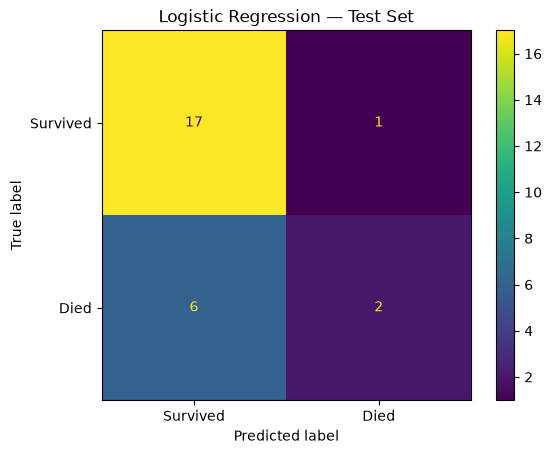

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_raw, y_pred, labels=[0, 1])

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Survived", "Died"]
).plot()

plt.title("Logistic Regression — Test Set")
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test_raw, y_pred)
precision = precision_score(y_test_raw, y_pred, zero_division=0)
recall = recall_score(y_test_raw, y_pred, zero_division=0)
f1 = f1_score(y_test_raw, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

Accuracy:  0.731
Precision: 0.667
Recall:    0.250
F1-score:  0.364


## Specificity

In [11]:
tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print(f"Specificity: {specificity:.3f}")

Specificity: 0.944


## ROC-AUC

ROC-AUC: 0.507


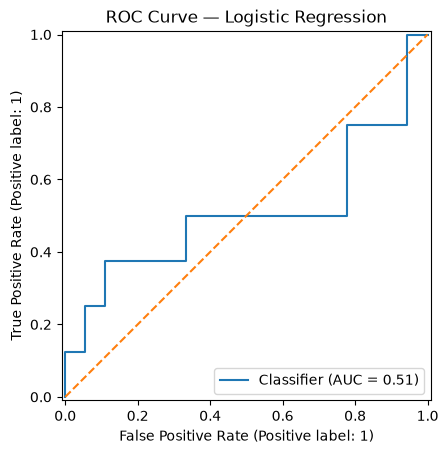

In [12]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

roc_auc = roc_auc_score(y_test_raw, y_proba)

print(f"ROC-AUC: {roc_auc:.3f}")

RocCurveDisplay.from_predictions(y_test_raw, y_proba)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve — Logistic Regression")
plt.show()

## Summary of Test Performance

In [13]:
metrics_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Mortality Recall",
        "Specificity",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

metrics_summary

,Metric,Score
0,Accuracy,0.730769
1,Precision,0.666667
2,Mortality Recall,0.250000
3,Specificity,0.944444
4,F1-score,0.363636
5,ROC-AUC,0.506944


## Final Evaluations

- The model's accuracy is 73.1%, representing only a modest improvement over the 69.2% majority-class baseline.
- Mortality recall is 25%, meaning that the model detected only 2 of the 8 deaths and missed the remaining 6.
- Specificity is 94.4%, meaning that the model correctly identified 17 of the 18 admissions that ended in survival.
- The ROC-AUC is 0.507, indicating little ability to discriminate between admissions ending in death and those ending in survival in this test sample.
- The test set contains only 26 admissions, so the performance estimates are highly uncertain and should not be generalised to clinical practice.

The evaluation results suggest that the Logistic Regression model has limited predictive performance for in-hospital mortality in this test sample. Although its accuracy of 73.1% exceeds the majority-class baseline, this improvement is modest and does not reflect reliable detection of deaths. The high specificity contrasts with the low mortality recall, demonstrating that the model was substantially better at identifying surviving admissions than detecting fatal outcomes. Furthermore, the ROC-AUC score of 0.507 suggests that the model had almost no ability to distinguish between the two outcomes based on its predicted probabilities.

These findings must be interpreted cautiously because the MIMIC-III demo dataset contains few admissions, and the held-out test set includes only eight deaths. Consequently, individual predictions have a substantial influence on the reported metrics, and the results cannot establish how well the model would generalise to a larger or different patient population. Further evaluation using a larger dataset, alongside appropriate validation, would be necessary before drawing stronger conclusions about its predictive performance.